In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [17]:
df = pd.read_excel("TugasBagianA_Bersih.xlsx", sheet_name="Data_Bersih")

df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"])
df["Month"] = df["Purchase_Date"].dt.month
df["Day_of_Month"] = df["Purchase_Date"].dt.day

df.head()

,Transaction_ID,Customer_ID,Age,Gender,City,Region,Membership_Level,Product_Category,Product_Name,Quantity,...,Discount_Percentage,Purchase_Amount,Payment_Method,Store_Type,Purchase_Date,Purchase_Hour,Purchase_Day,Customer_Satisfaction,Month,Day_of_Month
0,TRX-000001,CUST-02118,35,Female,Jakarta,Jabodetabek,Gold,Groceries,Assorted Snack Box,5,...,0.00,520000,QRIS,Online App,2026-01-01,3,Thursday,3,1,1
1,TRX-000002,CUST-03099,26,Male,Yogyakarta,Central Java,Basic,Home & Living,Air Purifier Mini,2,...,0.20,486400,Credit Card,Online App,2026-01-01,5,Thursday,1,1,1
2,TRX-000003,CUST-01259,37,Female,Sidoarjo,East Java,Basic,Fashion,Casual Chino Pants,2,...,0.10,768600,E-Wallet,Online App,2026-01-01,8,Thursday,1,1,1
3,TRX-000004,CUST-02153,33,Male,Medan,Sumatera,Premium,Home & Living,Ceramic Coffee Dripper,3,...,0.05,1214100,E-Wallet,Official Web,2026-01-01,8,Thursday,4,1,1
4,TRX-000005,CUST-00942,31,Male,Tangerang,Jabodetabek,Basic,Beauty & Health,Hydrating Facial Cleanser,3,...,0.05,262200,Debit Card,Flagship Store,2026-01-01,8,Thursday,5,1,1


In [18]:
print("Ukuran data :", df.shape)
print("Missing     :", df.isnull().sum().sum())
print("Maks diskon :", df["Discount_Percentage"].max())

Ukuran data : (9557, 21)
Missing     : 0
Maks diskon : 0.5


In [19]:
#Charts  Dinamika Waktu Belanja

In [20]:
import os
import matplotlib.dates as mdates

os.makedirs("charts", exist_ok=True)

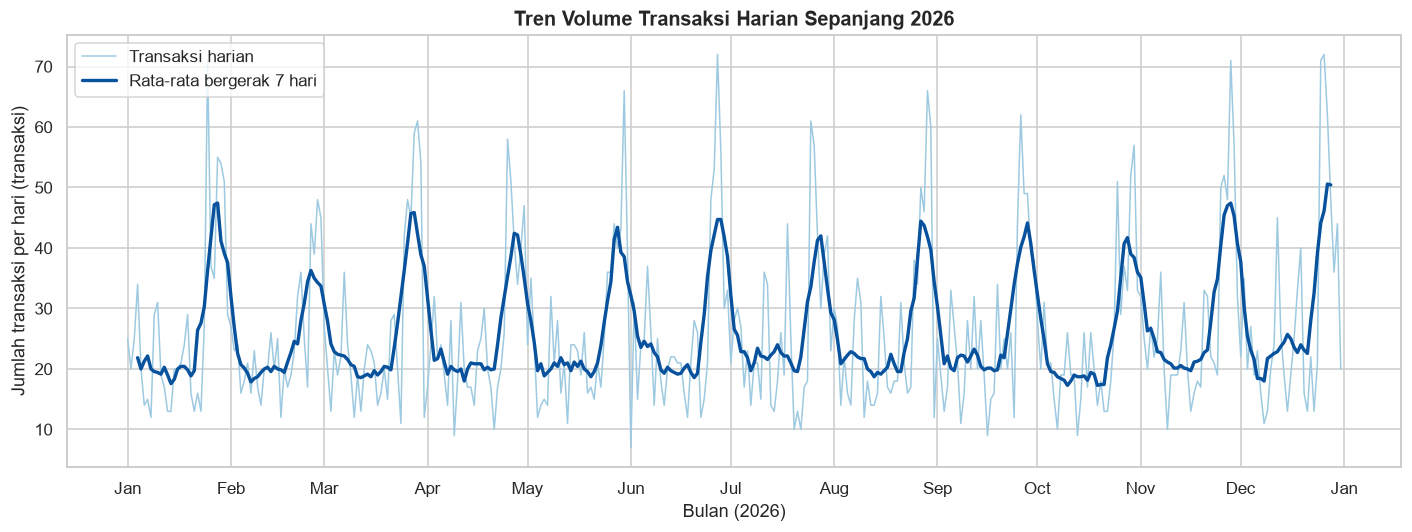

In [21]:
harian = df.groupby("Purchase_Date").size().rename("Transaksi").reset_index()
harian["MA7"] = harian["Transaksi"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(harian["Purchase_Date"], harian["Transaksi"], color="#9ecae1", linewidth=1, label="Transaksi harian")
ax.plot(harian["Purchase_Date"], harian["MA7"], color="#08519c", linewidth=2.2, label="Rata-rata bergerak 7 hari")
ax.set_title("Tren Volume Transaksi Harian Sepanjang 2026", fontsize=13, fontweight="bold")
ax.set_xlabel("Bulan (2026)")
ax.set_ylabel("Jumlah transaksi per hari (transaksi)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
plt.tight_layout()
plt.savefig("charts/H1_tren_harian.png", dpi=300, bbox_inches="tight")
plt.show()

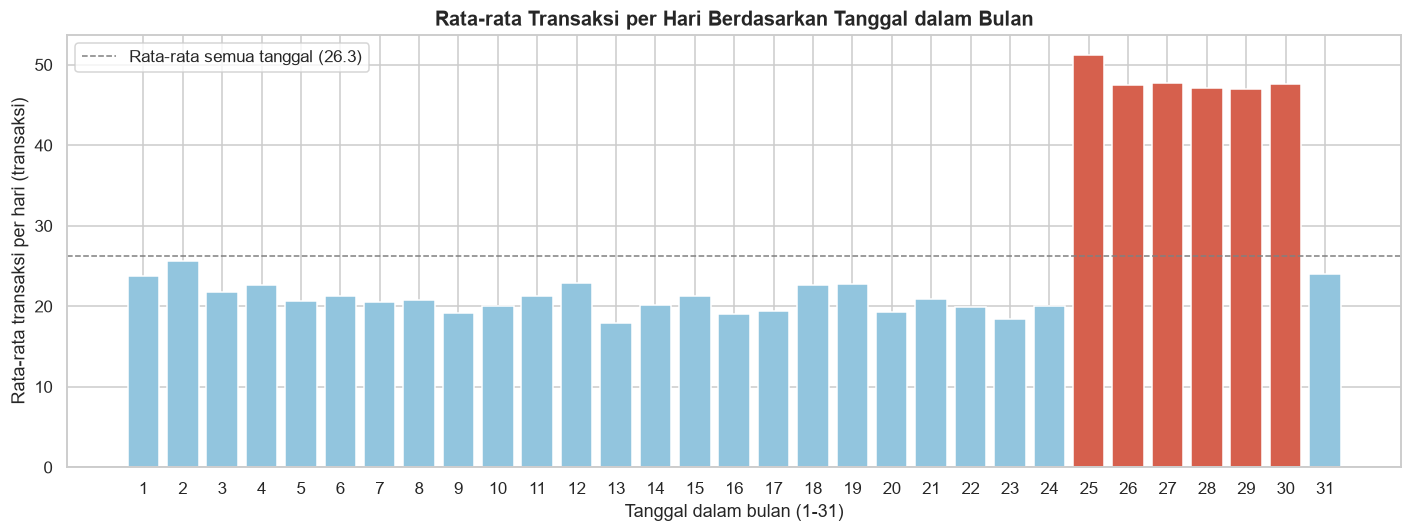

In [22]:
per_tanggal = harian.groupby(harian["Purchase_Date"].dt.day)["Transaksi"].mean()
batas = per_tanggal.mean() * 1.15
warna = ["#d6604d" if v >= batas else "#92c5de" for v in per_tanggal.values]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(per_tanggal.index, per_tanggal.values, color=warna)
ax.axhline(per_tanggal.mean(), color="gray", linestyle="--", linewidth=1,
           label=f"Rata-rata semua tanggal ({per_tanggal.mean():.1f})")
ax.set_title("Rata-rata Transaksi per Hari Berdasarkan Tanggal dalam Bulan", fontsize=13, fontweight="bold")
ax.set_xlabel("Tanggal dalam bulan (1-31)")
ax.set_ylabel("Rata-rata transaksi per hari (transaksi)")
ax.set_xticks(range(1, 32))
ax.legend()
plt.tight_layout()
plt.savefig("charts/H1_tanggal_dalam_bulan.png", dpi=300, bbox_inches="tight")
plt.show()

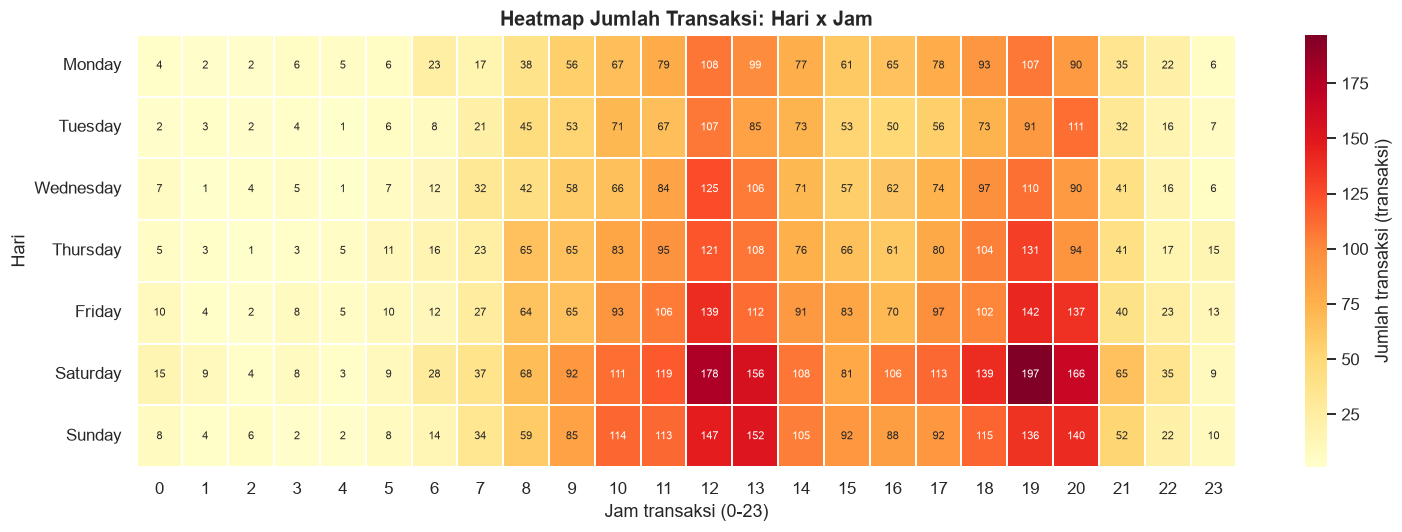

In [23]:
urutan_hari = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = (df.pivot_table(index="Purchase_Day", columns="Purchase_Hour",
                        values="Transaction_ID", aggfunc="count", fill_value=0)
           .reindex(urutan_hari).reindex(columns=range(24), fill_value=0))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt="d", annot_kws={"size": 7}, linewidths=0.3,
            cbar_kws={"label": "Jumlah transaksi (transaksi)"}, ax=ax)
ax.set_title("Heatmap Jumlah Transaksi: Hari x Jam", fontsize=13, fontweight="bold")
ax.set_xlabel("Jam transaksi (0-23)")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig("charts/H1_heatmap_hari_jam.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
#Charts Kontribusi Geografis

In [25]:
from matplotlib.patches import Patch

def fmt_id(x, nd=0):
    """Format angka gaya Indonesia: titik ribuan, koma desimal."""
    return f"{x:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")

region = (df.groupby("Region")
            .agg(Transaksi=("Transaction_ID", "count"), Nilai=("Purchase_Amount", "sum"))
            .sort_values("Nilai", ascending=False))
region["Nilai_M"] = region["Nilai"] / 1e9
region["Pct_Trx"] = region["Transaksi"] / region["Transaksi"].sum() * 100
region["Pct_Nilai"] = region["Nilai"] / region["Nilai"].sum() * 100

urut_region = region.index.tolist()
warna_region = dict(zip(urut_region, sns.color_palette("colorblind", len(urut_region))))

region.round(2)

,Transaksi,Nilai,Nilai_M,Pct_Trx,Pct_Nilai
Region,,,,,
Jabodetabek,3932,6893969150,6.89,41.14,36.19
West Java,1650,3381092550,3.38,17.26,17.75
East Java,1518,3349590850,3.35,15.88,17.58
Central Java,1467,3102443050,3.10,15.35,16.29
Sumatera,990,2322451000,2.32,10.36,12.19


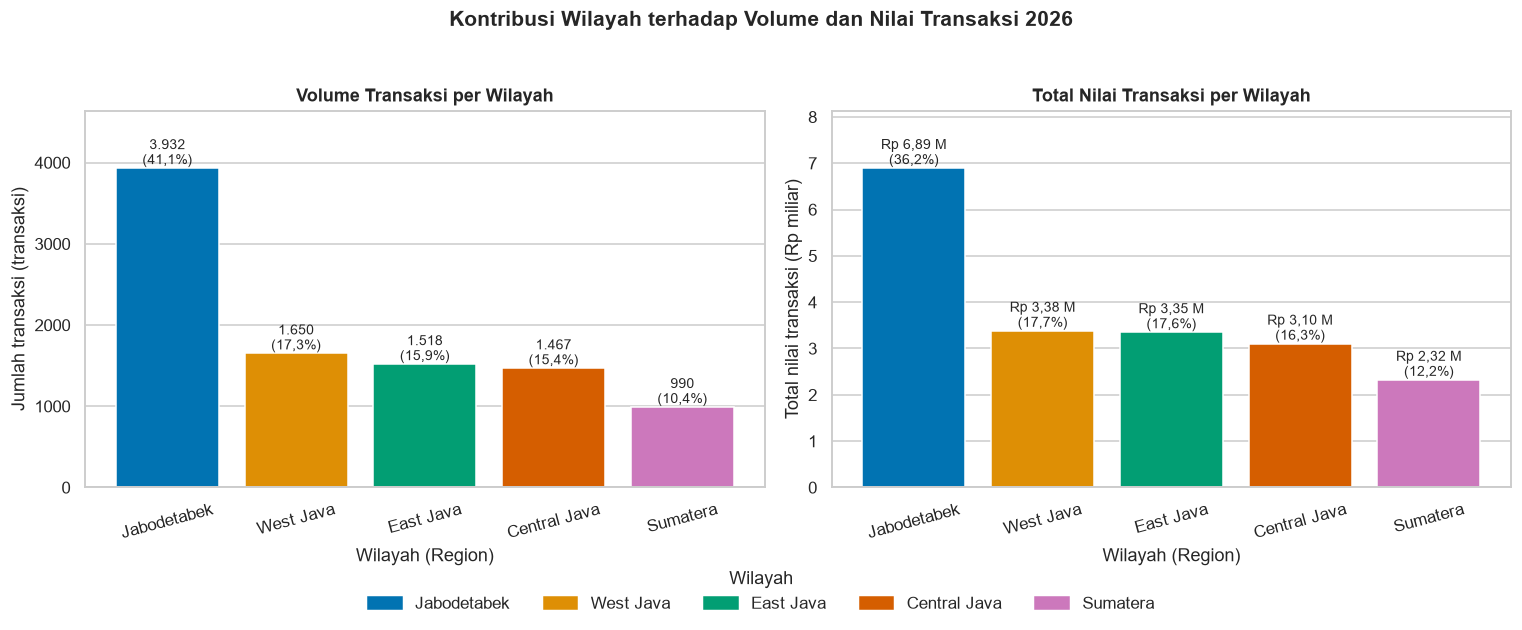

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].bar(urut_region, region["Transaksi"], color=[warna_region[r] for r in urut_region])
for i, r in enumerate(urut_region):
    axes[0].text(i, region.loc[r, "Transaksi"],
                 f"{fmt_id(region.loc[r, 'Transaksi'])}\n({fmt_id(region.loc[r, 'Pct_Trx'], 1)}%)",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_title("Volume Transaksi per Wilayah", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Wilayah (Region)")
axes[0].set_ylabel("Jumlah transaksi (transaksi)")
axes[0].set_ylim(0, region["Transaksi"].max() * 1.18)

axes[1].bar(urut_region, region["Nilai_M"], color=[warna_region[r] for r in urut_region])
for i, r in enumerate(urut_region):
    axes[1].text(i, region.loc[r, "Nilai_M"],
                 f"Rp {fmt_id(region.loc[r, 'Nilai_M'], 2)} M\n({fmt_id(region.loc[r, 'Pct_Nilai'], 1)}%)",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_title("Total Nilai Transaksi per Wilayah", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Wilayah (Region)")
axes[1].set_ylabel("Total nilai transaksi (Rp miliar)")
axes[1].set_ylim(0, region["Nilai_M"].max() * 1.18)

for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(False, axis="x")

fig.legend(handles=[Patch(color=warna_region[r], label=r) for r in urut_region],
           title="Wilayah", loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.04), frameon=False)
fig.suptitle("Kontribusi Wilayah terhadap Volume dan Nilai Transaksi 2026", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("charts/H2_region_volume_nilai.png", dpi=300, bbox_inches="tight")
plt.show()

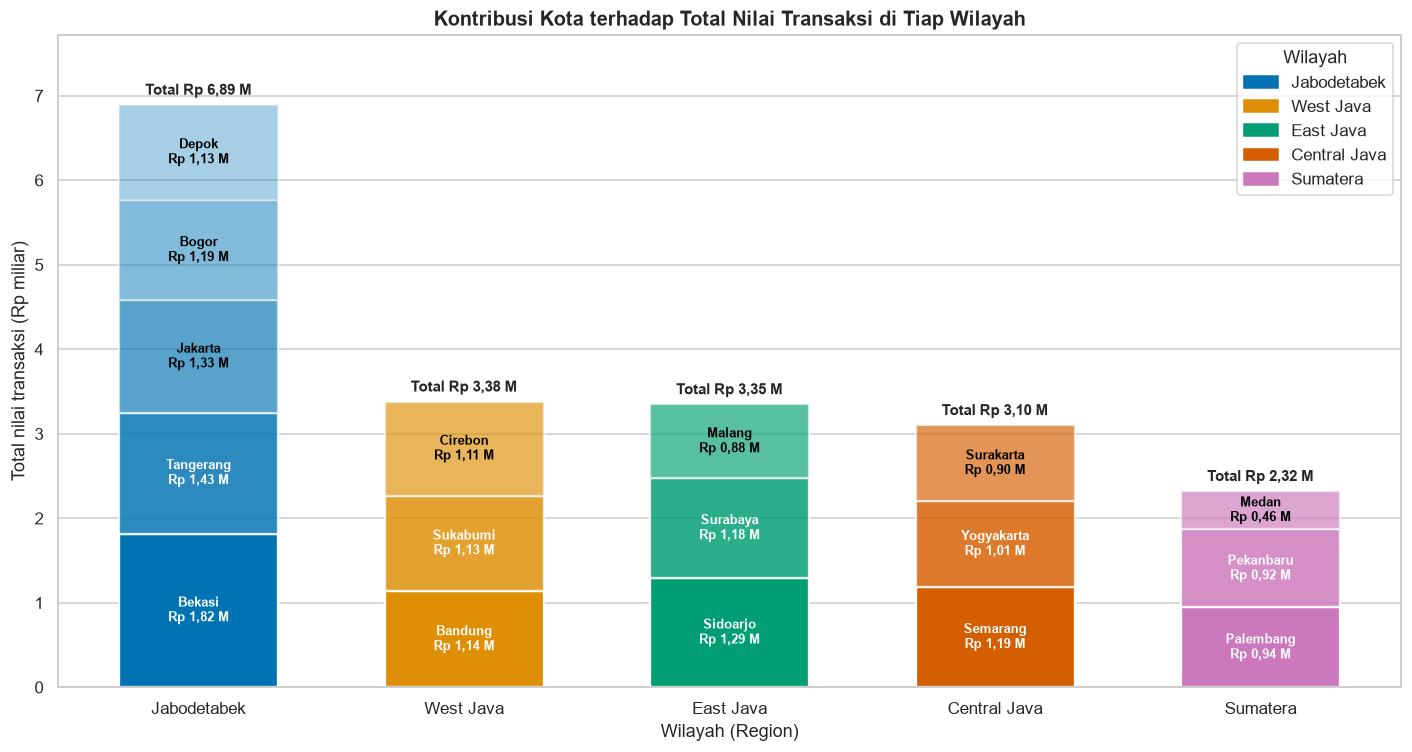

In [27]:
kota = (df.groupby(["Region", "City"])["Purchase_Amount"].sum().div(1e9)
          .rename("Nilai_M").reset_index())

fig, ax = plt.subplots(figsize=(13, 7))
for i, r in enumerate(urut_region):
    sub = kota[kota["Region"] == r].sort_values("Nilai_M", ascending=False)
    bawah = 0
    for j, (_, baris) in enumerate(sub.iterrows()):
        alpha = max(1.0 - j * 0.17, 0.35)
        ax.bar(i, baris["Nilai_M"], bottom=bawah, color=warna_region[r], alpha=alpha,
               edgecolor="white", linewidth=1.5, width=0.6)
        ax.text(i, bawah + baris["Nilai_M"] / 2,
                f"{baris['City']}\nRp {fmt_id(baris['Nilai_M'], 2)} M",
                ha="center", va="center", fontsize=8.5,
                color="black" if alpha < 0.7 else "white", fontweight="bold")
        bawah += baris["Nilai_M"]
    ax.text(i, bawah + 0.08, f"Total Rp {fmt_id(bawah, 2)} M",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticks(range(len(urut_region)))
ax.set_xticklabels(urut_region)
ax.set_xlabel("Wilayah (Region)")
ax.set_ylabel("Total nilai transaksi (Rp miliar)")
ax.set_title("Kontribusi Kota terhadap Total Nilai Transaksi di Tiap Wilayah", fontsize=13, fontweight="bold")
ax.set_ylim(0, region["Nilai_M"].max() * 1.12)
ax.grid(False, axis="x")
ax.legend(handles=[Patch(color=warna_region[r], label=r) for r in urut_region], title="Wilayah", loc="upper right")
plt.tight_layout()
plt.savefig("charts/H2_kota_per_region.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
tabel = (df.groupby(["Region", "City"])
           .agg(Transaksi=("Transaction_ID", "count"), Nilai=("Purchase_Amount", "sum"))
           .reset_index())
tabel["Pct_trx_dlm_wilayah"] = (tabel["Transaksi"] / tabel.groupby("Region")["Transaksi"].transform("sum") * 100).round(1)
tabel["Pct_nilai_dlm_wilayah"] = (tabel["Nilai"] / tabel.groupby("Region")["Nilai"].transform("sum") * 100).round(1)
tabel["Nilai_Rp_miliar"] = (tabel["Nilai"] / 1e9).round(2)
tabel = tabel.drop(columns="Nilai").sort_values(["Region", "Nilai_Rp_miliar"], ascending=[True, False])
tabel

,Region,City,Transaksi,Pct_trx_dlm_wilayah,Pct_nilai_dlm_wilayah,Nilai_Rp_miliar
0,Central Java,Semarang,550,37.5,38.3,1.19
2,Central Java,Yogyakarta,496,33.8,32.6,1.01
1,Central Java,Surakarta,421,28.7,29.1,0.90
4,East Java,Sidoarjo,504,33.2,38.7,1.29
5,East Java,Surabaya,501,33.0,35.1,1.18
3,East Java,Malang,513,33.8,26.2,0.88
6,Jabodetabek,Bekasi,757,19.3,26.4,1.82
10,Jabodetabek,Tangerang,730,18.6,20.7,1.43
9,Jabodetabek,Jakarta,759,19.3,19.3,1.33
7,Jabodetabek,Bogor,769,19.6,17.3,1.19


In [29]:
#Pengaruh Membership & Kategori Produk:

In [30]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

def rp_singkat(x, _):
    if x >= 1e9: return f"{x/1e9:g} M"
    if x >= 1e6: return f"{x/1e6:g} jt"
    if x >= 1e3: return f"{x/1e3:g} rb"
    return f"{x:g}"

urut_member = ["Basic", "Silver", "Gold", "Premium"]
warna_member = dict(zip(urut_member, sns.color_palette("YlGnBu", 6)[1:5]))

mean_props = dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6)
flier_props = dict(marker="o", markersize=2.5, alpha=0.35, markerfacecolor="gray", markeredgecolor="none")
legenda_box = [
    Line2D([0], [0], color="black", linewidth=2, label="Median (garis tengah kotak)"),
    Line2D([0], [0], marker="D", color="w", markerfacecolor="white", markeredgecolor="black", markersize=7, label="Rata-rata"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", alpha=0.6, markersize=5, label="Outlier (metode IQR)"),
]

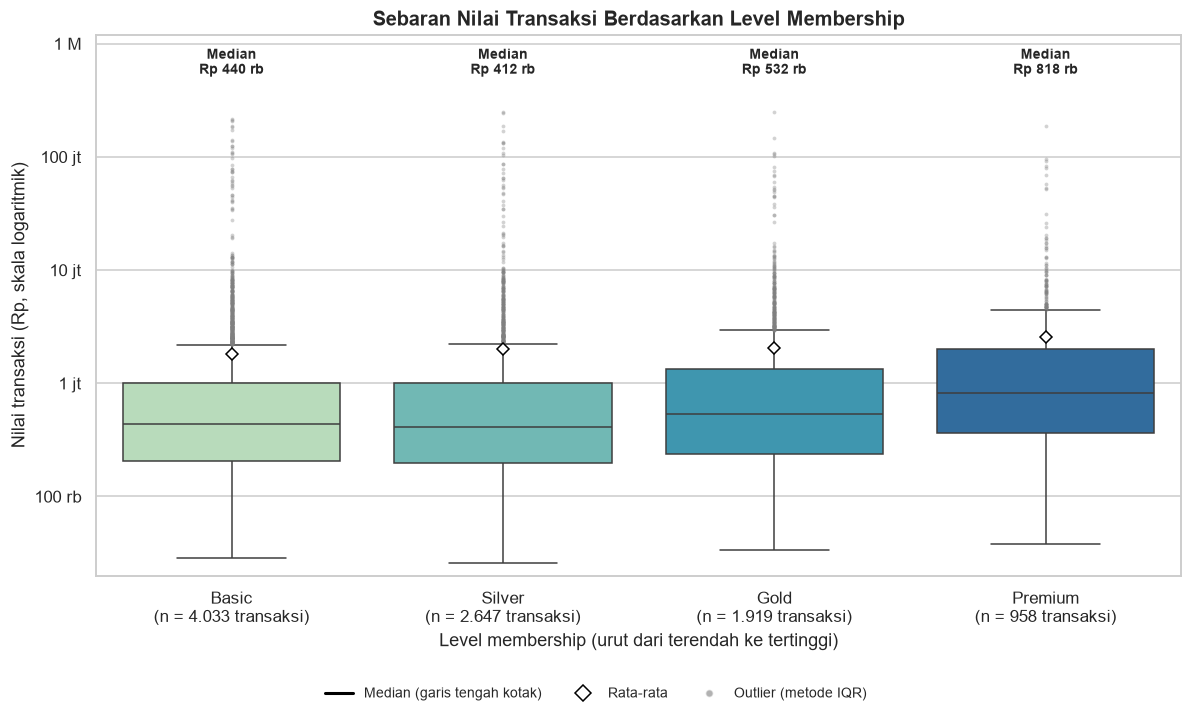

In [31]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.boxplot(data=df, x="Membership_Level", y="Purchase_Amount", order=urut_member,
            hue="Membership_Level", hue_order=urut_member, palette=warna_member, legend=False,
            showmeans=True, meanprops=mean_props, flierprops=flier_props, ax=ax)
ax.set_yscale("log")
ax.set_ylim(2e4, 1.2e9)
ax.yaxis.set_major_formatter(FuncFormatter(rp_singkat))

n_per = df["Membership_Level"].value_counts()
med_per = df.groupby("Membership_Level")["Purchase_Amount"].median()
ax.set_xticks(range(4))
ax.set_xticklabels([f"{m}\n(n = {fmt_id(n_per[m])} transaksi)" for m in urut_member])
for i, m in enumerate(urut_member):
    ax.text(i, 5e8, f"Median\nRp {fmt_id(med_per[m] / 1e3)} rb", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title("Sebaran Nilai Transaksi Berdasarkan Level Membership", fontsize=13, fontweight="bold")
ax.set_xlabel("Level membership (urut dari terendah ke tertinggi)")
ax.set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
fig.legend(handles=legenda_box, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("charts/H3_boxplot_membership.png", dpi=300, bbox_inches="tight")
plt.show()

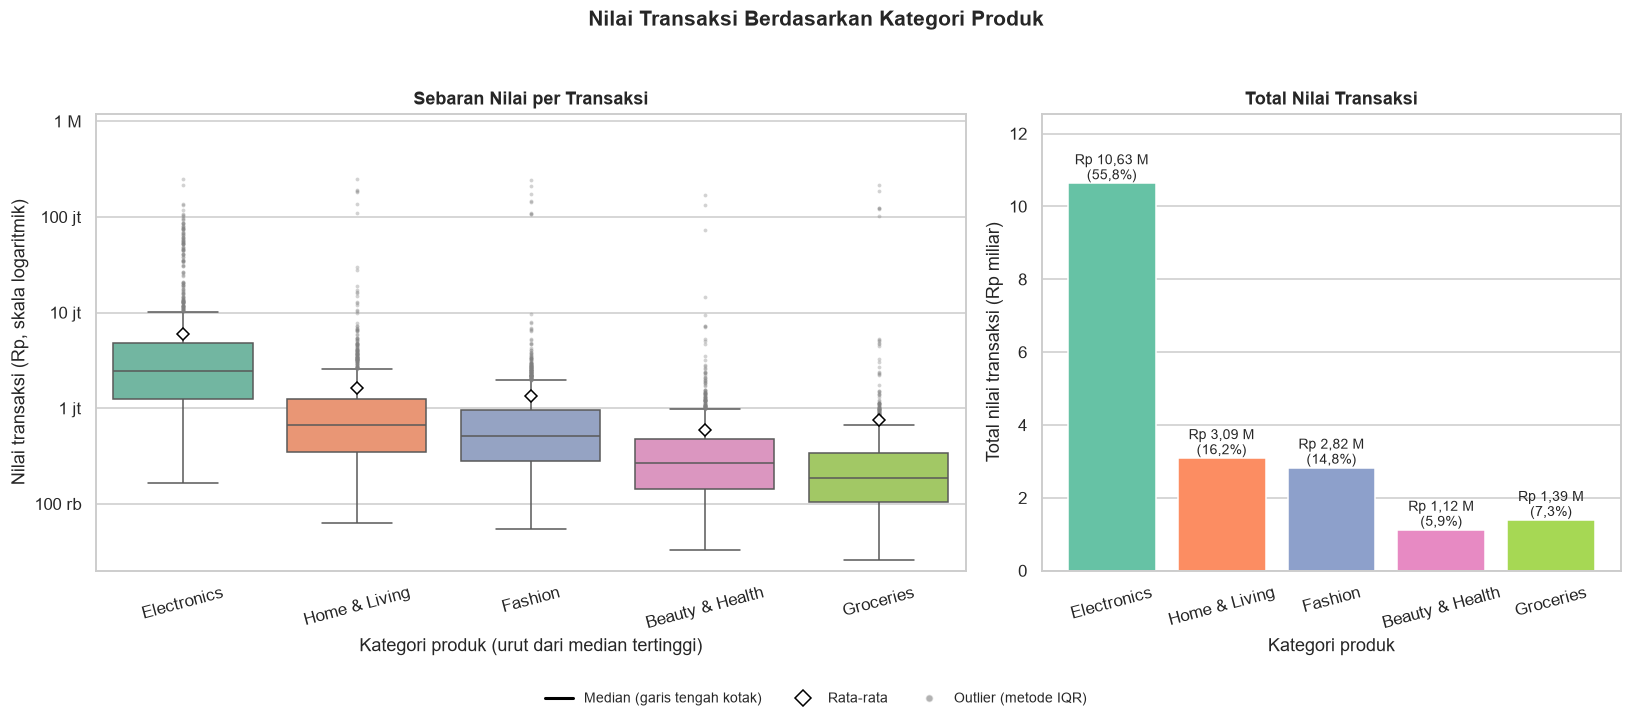

In [32]:
urut_kat = df.groupby("Product_Category")["Purchase_Amount"].median().sort_values(ascending=False).index.tolist()
warna_kat = dict(zip(urut_kat, sns.color_palette("Set2", len(urut_kat))))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})

sns.boxplot(data=df, x="Product_Category", y="Purchase_Amount", order=urut_kat,
            hue="Product_Category", hue_order=urut_kat, palette=warna_kat, legend=False,
            showmeans=True, meanprops=mean_props, flierprops=flier_props, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_ylim(2e4, 1.2e9)
axes[0].yaxis.set_major_formatter(FuncFormatter(rp_singkat))
axes[0].set_title("Sebaran Nilai per Transaksi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Kategori produk (urut dari median tertinggi)")
axes[0].set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
axes[0].tick_params(axis="x", rotation=15)

total = (df.groupby("Product_Category")["Purchase_Amount"].sum() / 1e9).reindex(urut_kat)
pct = total / total.sum() * 100
axes[1].bar(urut_kat, total.values, color=[warna_kat[k] for k in urut_kat])
for i, k in enumerate(urut_kat):
    axes[1].text(i, total[k], f"Rp {fmt_id(total[k], 2)} M\n({fmt_id(pct[k], 1)}%)", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, total.max() * 1.18)
axes[1].set_title("Total Nilai Transaksi", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kategori produk")
axes[1].set_ylabel("Total nilai transaksi (Rp miliar)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(False, axis="x")

fig.suptitle("Nilai Transaksi Berdasarkan Kategori Produk", fontsize=14, fontweight="bold")
fig.legend(handles=legenda_box, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig("charts/H3_boxplot_kategori.png", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
median_silang = (df.pivot_table(index="Membership_Level", columns="Product_Category",
                                values="Purchase_Amount", aggfunc="median")
                   .reindex(urut_member)[urut_kat] / 1e3).round(0)
median_silang

Product_Category,Electronics,Home & Living,Fashion,Beauty & Health,Groceries
Membership_Level,,,,,
Basic,2243.0,615.0,483.0,258.0,177.0
Silver,2450.0,619.0,488.0,256.0,177.0
Gold,2474.0,604.0,516.0,259.0,191.0
Premium,2993.0,1117.0,789.0,345.0,276.0
